# Introduccion

#### Desarrollar un modelo de scoring crediticio interno y una simulación de capital económico, y valorizar económicamente su aporte frente al enfoque regulatorio estandarizado — demostrando si un banco, con herramientas propias, puede medir su riesgo real mejor que lo que exige el regulador de forma simple.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# EDA

In [2]:
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

df_raw = pd.read_csv('https://raw.githubusercontent.com/palasatenea66/DATASETS/main/credito.csv')
df_raw.head()

,ID,ingresos,edad,provincia_codigo,bancarizado,BCRA_Peor_Situacion,Cantidad_consultas_7_dias,Compromisos_Mensual,Endeudamiento_Externo,Nivel_Socioeconomico,Deuda_normal,Deuda_30,Deuda_90,deuda_120,deuda_180,canti_moras,autonomo,Es_jubilado,relacion_dependencia,dias_atraso,Cuota,cant_cuotas,Monto_Otorgado,PRODUCTO,PROVINCIA,moroso
0,1,35000.0,35,X,1,1,1.0,9976.0,170000.0,4,170000.0,0.0,0.0,0.0,0.0,0,F,F,UNIVERSIDAD NACIONAL DE CORDOBA ...,143,8957.00,12,50000.0,DS_SUCURSAL_ORO,CORDOBA,1
1,2,50000.0,24,B,1,3,0.0,16807.0,236000.0,4,187000.0,0.0,11000.0,0.0,38000.0,0,F,F,POLICIA FEDERAL ARGENTINA ...,174,6874.49,9,25000.0,DS_BASICO,BUENOS AIRES,1
2,3,50000.0,42,X,1,1,5.0,42959.0,683343.0,3,683343.0,0.0,0.0,0.0,0.0,0,F,F,MINISTERIO DE EDUCACION ...,0,4191.93,12,23400.0,DS_SUCURSAL_ORO,CORDOBA,0
3,4,32000.0,21,H,1,1,3.0,7583.0,76000.0,5,76000.0,0.0,0.0,0.0,0.0,0,F,F,CONTADURIA GENERAL DEL EJERCITO ...,23,3667.60,12,16000.0,DS_BASICO,CHACO,0
4,5,50000.0,21,Z,1,1,4.0,1040.0,23000.0,5,23000.0,0.0,0.0,0.0,0.0,0,F,F,CONTADURIA GENERAL DEL EJERCITO ...,0,3891.04,6,15000.0,DS_SUCURSAL_ORO,SANTA CRUZ,0


In [3]:
print("="*60)
print("DIMENSIONES Y ESTRUCTURA")
print("="*60)
print(f"Filas: {df_raw.shape[0]} | Columnas: {df_raw.shape[1]}")
print(f"\nTipos de datos:\n{df_raw.dtypes.value_counts()}")

print("\n" + "="*60)
print("VALORES FALTANTES")
print("="*60)
nulos = df_raw.isnull().sum()
print(nulos[nulos > 0])

print("\n" + "="*60)
print("VARIABLE OBJETIVO (moroso)")
print("="*60)
print(df_raw['moroso'].value_counts())
print(df_raw['moroso'].value_counts(normalize=True).round(4) * 100, "%")

print("\n" + "="*60)
print("ESTADÍSTICOS DESCRIPTIVOS — NUMÉRICAS")
print("="*60)
print(df_raw.describe().T)

print("\n" + "="*60)
print("ESTADÍSTICOS DESCRIPTIVOS — CATEGÓRICAS")
print("="*60)
print(df_raw.describe(include='object').T)

DIMENSIONES Y ESTRUCTURA
Filas: 1190 | Columnas: 26

Tipos de datos:
float64    11
int64       9
object      6
Name: count, dtype: int64

VALORES FALTANTES
Cantidad_consultas_7_dias      1
relacion_dependencia         138
dtype: int64

VARIABLE OBJETIVO (moroso)
moroso
0    921
1    269
Name: count, dtype: int64
moroso
0    77.39
1    22.61
Name: proportion, dtype: float64 %

ESTADÍSTICOS DESCRIPTIVOS — NUMÉRICAS
                            count           mean            std      min  \
ID                         1190.0     595.500000     343.667717      1.0   
ingresos                   1190.0   53437.669538   43665.378404  12924.0   
edad                       1190.0      43.843697      13.781331     18.0   
bancarizado                1190.0       0.642017       0.479609      0.0   
BCRA_Peor_Situacion        1190.0       0.889076       1.231544     -1.0   
Cantidad_consultas_7_dias  1189.0       1.879731       2.768540      0.0   
Compromisos_Mensual        1190.0    9321.036134   

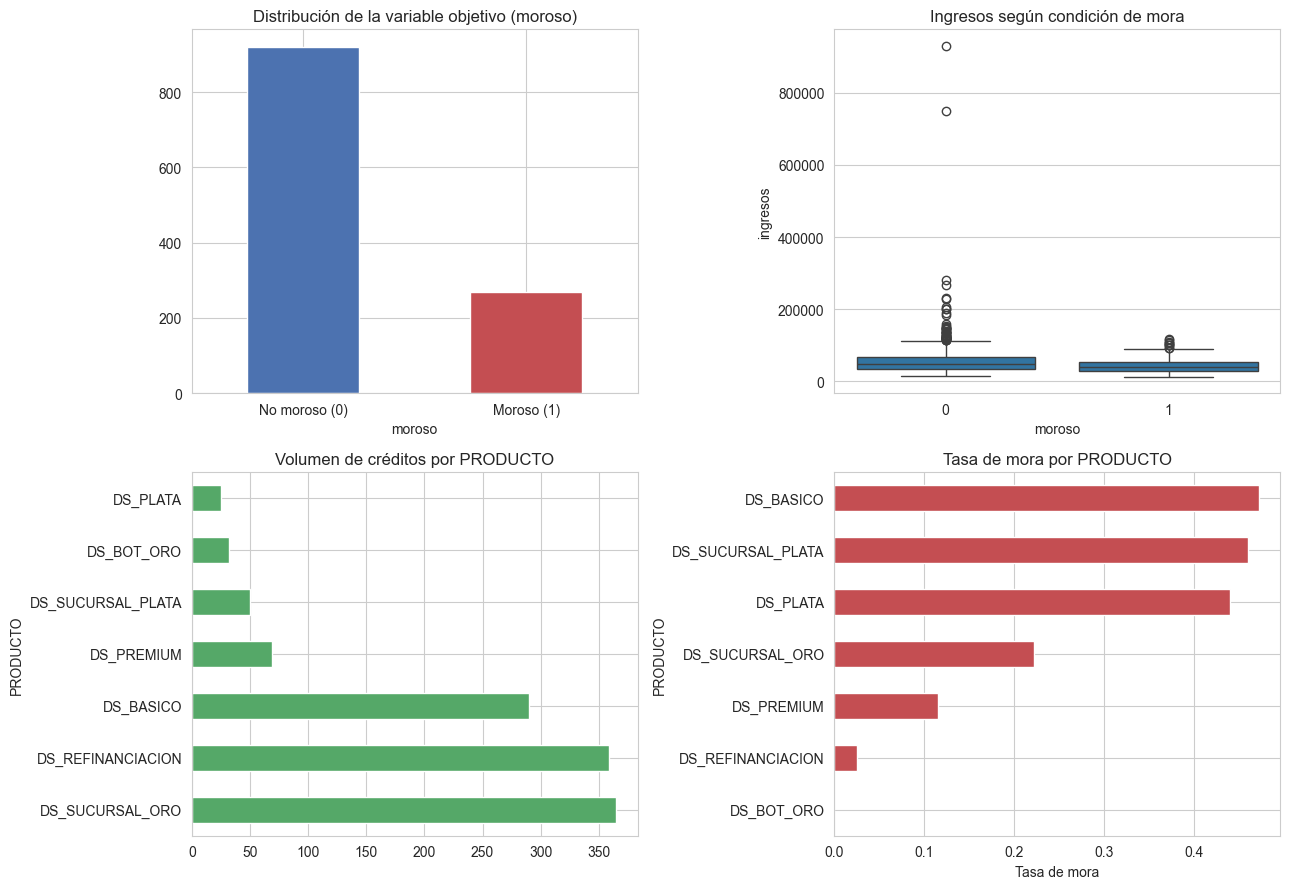

In [4]:
# --- Visualizaciones ---
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Distribución del target
df_raw['moroso'].value_counts().plot(kind='bar', ax=axes[0,0], color=['#4C72B0', '#C44E52'])
axes[0,0].set_title('Distribución de la variable objetivo (moroso)')
axes[0,0].set_xticklabels(['No moroso (0)', 'Moroso (1)'], rotation=0)

# Distribución de ingresos por moroso
sns.boxplot(data=df_raw, x='moroso', y='ingresos', ax=axes[0,1])
axes[0,1].set_title('Ingresos según condición de mora')

# Distribución de PRODUCTO
df_raw['PRODUCTO'].value_counts().plot(kind='barh', ax=axes[1,0], color='#55A868')
axes[1,0].set_title('Volumen de créditos por PRODUCTO')

# Tasa de mora por PRODUCTO
df_raw.groupby('PRODUCTO')['moroso'].mean().sort_values().plot(kind='barh', ax=axes[1,1], color='#C44E52')
axes[1,1].set_title('Tasa de mora por PRODUCTO')
axes[1,1].set_xlabel('Tasa de mora')

plt.tight_layout()
plt.savefig('eda_intro.png', dpi=110)
plt.show()

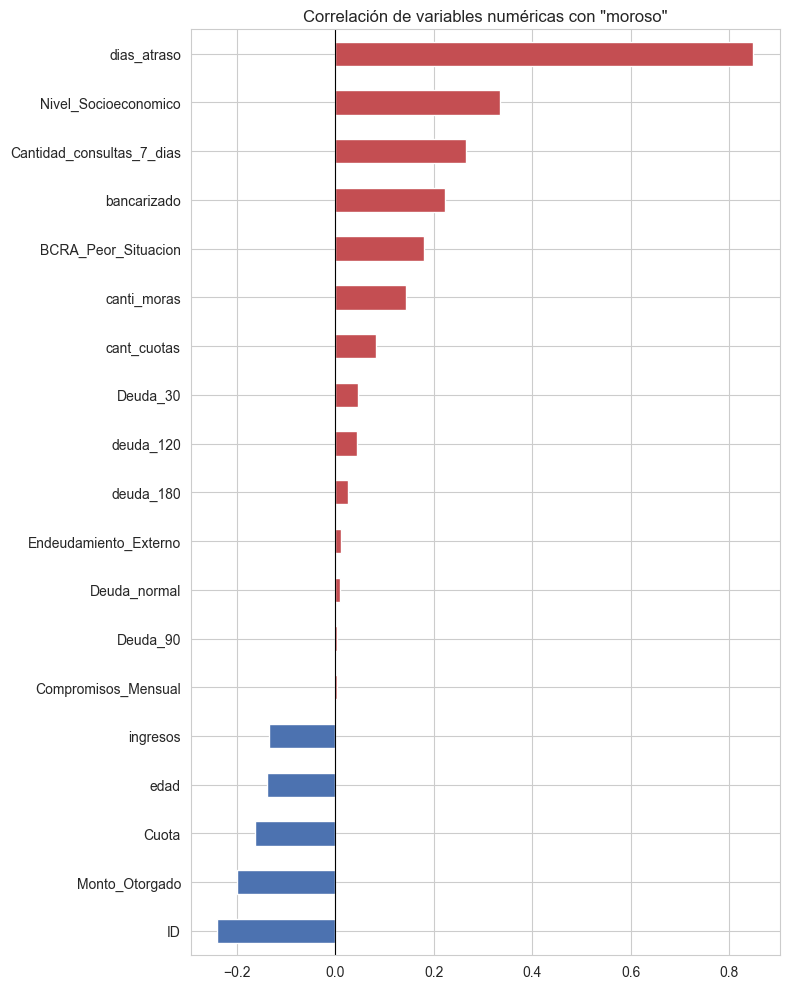

In [5]:
# Matriz de correlación de variables numéricas con el target
plt.figure(figsize=(8, 10))
num_cols = df_raw.select_dtypes(include=[np.number]).columns
corr_target = df_raw[num_cols].corr()['moroso'].drop('moroso').sort_values()
corr_target.plot(kind='barh', color=np.where(corr_target > 0, '#C44E52', '#4C72B0'))
plt.title('Correlación de variables numéricas con "moroso"')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('eda_correlaciones.png', dpi=110)
plt.show()

# Limpieza y definición de scope

In [6]:
from sklearn.model_selection import train_test_split

df = df_raw[df_raw['PRODUCTO'] != 'DS_REFINANCIACION'].copy()

# Nivel_Socioeconomico: separar centinela -1 (exclusivo de refinanciación) de la escala real
df['nse_valor'] = np.where(df['Nivel_Socioeconomico'] == -1, np.nan, df['Nivel_Socioeconomico'])

# Imputar único nulo de consultas con la mediana
df['Cantidad_consultas_7_dias'] = df['Cantidad_consultas_7_dias'].fillna(df['Cantidad_consultas_7_dias'].median())

# Dataset final: excluye leakage (dias_atraso, canti_moras), identificadores y variables sin señal
# (autonomo_flag, es_jubilado_flag, tiene_relacion_dependencia se descartaron por IV≈0 en la exploración previa)
# provincia_codigo se deja CRUDA: el binning por similitud de WOE la agrupa mejor que una regla manual de volumen
cols_modelo = ['ingresos', 'edad', 'Cantidad_consultas_7_dias', 'Compromisos_Mensual',
               'Deuda_normal', 'Cuota', 'cant_cuotas', 'Monto_Otorgado', 'nse_valor',
               'deuda_180', 'PRODUCTO', 'provincia_codigo', 'BCRA_Peor_Situacion', 'moroso']

df_model = df[cols_modelo].copy()

X = df_model.drop(columns=['moroso'])
y = df_model['moroso']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

print("Shape scope final (post exclusión refinanciación):", df_model.shape, "| PD cartera:", y.mean().round(4))
print("Train:", X_train.shape, "| Test:", X_test.shape)


Shape scope final (post exclusión refinanciación): (831, 14) | PD cartera: 0.3129
Train: (623, 13) | Test: (208, 13)


# Funciones WOE/IV y transformación de train/test

In [7]:
def calcular_woe_iv(df_in, feature, target):
    grouped = df_in.groupby(feature, observed=True)[target].agg(['count', 'sum'])
    grouped.columns = ['total', 'malos']
    grouped['buenos'] = grouped['total'] - grouped['malos']
    total_malos, total_buenos = grouped['malos'].sum(), grouped['buenos'].sum()
    grouped['dist_malos'] = (grouped['malos'] + 0.5) / (total_malos + 0.5 * len(grouped))
    grouped['dist_buenos'] = (grouped['buenos'] + 0.5) / (total_buenos + 0.5 * len(grouped))
    grouped['woe'] = np.log(grouped['dist_buenos'] / grouped['dist_malos'])
    grouped['iv_bin'] = (grouped['dist_buenos'] - grouped['dist_malos']) * grouped['woe']
    return grouped, grouped['iv_bin'].sum()

def binning_numerico_monotono(train_df, var, target, n_bins_inicial=10, min_frac=0.05):
    """Fusiona bins de quintiles finos hasta lograr monotonía y tamaño mínimo por bin."""
    _, edges = pd.qcut(train_df[var], q=n_bins_inicial, duplicates='drop', retbins=True)
    edges = list(edges)
    edges[0], edges[-1] = -np.inf, np.inf
    min_count = min_frac * len(train_df)
    while True:
        binned = pd.cut(train_df[var], bins=edges)
        stats = train_df.groupby(binned, observed=True)[target].agg(['mean', 'count']).dropna()
        rates, counts = stats['mean'].values, stats['count'].values
        if len(rates) <= 2:
            break
        if counts.min() < min_count:
            idx_chico = int(np.argmin(counts))
            if idx_chico == 0:
                del edges[1]
            else:
                del edges[idx_chico]
            continue
        diffs = np.diff(rates)
        if np.all(diffs >= 0) or np.all(diffs <= 0):
            break
        signo_ref = np.sign(diffs[np.argmax(np.abs(diffs))])
        violaciones = [i for i in range(len(diffs)) if diffs[i] != 0 and np.sign(diffs[i]) != signo_ref]
        i_fusionar = violaciones[0] + 1 if violaciones else 1
        del edges[i_fusionar]
    return edges

def binning_categorico_por_similitud(train_df, var, target, min_frac=0.03):
    """Ordena categorías por tasa de mora y fusiona la más chica con su vecina más parecida en riesgo."""
    stats = train_df.groupby(var, observed=True)[target].agg(['mean', 'count']).sort_values('mean')
    grupos = {cat: [cat] for cat in stats.index}
    min_count = min_frac * len(train_df)
    orden = list(stats.index)
    while True:
        cats_activas = [c for c in orden if c in grupos]
        conteos_activos = [stats.loc[grupos[c], 'count'].sum() for c in cats_activas]
        if min(conteos_activos) >= min_count or len(cats_activas) <= 2:
            break
        idx_chico = int(np.argmin(conteos_activos))
        cat_chica = cats_activas[idx_chico]
        if idx_chico == 0:
            vecino = cats_activas[1]
        elif idx_chico == len(cats_activas) - 1:
            vecino = cats_activas[-2]
        else:
            izq, der = cats_activas[idx_chico - 1], cats_activas[idx_chico + 1]
            tasa_chica = (stats.loc[grupos[cat_chica], 'mean'] * stats.loc[grupos[cat_chica], 'count']).sum() / stats.loc[grupos[cat_chica], 'count'].sum()
            tasa_izq = (stats.loc[grupos[izq], 'mean'] * stats.loc[grupos[izq], 'count']).sum() / stats.loc[grupos[izq], 'count'].sum()
            tasa_der = (stats.loc[grupos[der], 'mean'] * stats.loc[grupos[der], 'count']).sum() / stats.loc[grupos[der], 'count'].sum()
            vecino = izq if abs(tasa_chica - tasa_izq) <= abs(tasa_chica - tasa_der) else der
        grupos[vecino] = grupos[vecino] + grupos[cat_chica]
        del grupos[cat_chica]
    mapa_final = {}
    for grupo_rep, miembros in grupos.items():
        nombre_grupo = "+".join(sorted(str(m) for m in miembros)) if len(miembros) > 1 else str(grupo_rep)
        for m in miembros:
            mapa_final[m] = nombre_grupo
    return mapa_final

vars_numericas = ['ingresos', 'edad', 'Cantidad_consultas_7_dias', 'Compromisos_Mensual',
                   'Deuda_normal', 'Cuota', 'cant_cuotas', 'Monto_Otorgado', 'nse_valor', 'deuda_180']
vars_categoricas = ['PRODUCTO', 'provincia_codigo', 'BCRA_Peor_Situacion']

train_bin = X_train.copy()
train_bin['moroso'] = y_train.values

X_train_woe = pd.DataFrame(index=X_train.index)
X_test_woe = pd.DataFrame(index=X_test.index)
iv_resultados = {}
bin_edges_finales = {}
mapas_categoricos = {}

for var in vars_numericas:
    edges = binning_numerico_monotono(train_bin, var, 'moroso')
    bin_edges_finales[var] = edges
    train_bin[f'{var}_b'] = pd.cut(train_bin[var], bins=edges)
    tabla, iv = calcular_woe_iv(train_bin, f'{var}_b', 'moroso')
    iv_resultados[var] = iv
    woe_dict = tabla['woe'].to_dict()
    X_train_woe[f'{var}_woe'] = train_bin[f'{var}_b'].map(woe_dict).astype(float)
    X_test_woe[f'{var}_woe'] = pd.cut(X_test[var], bins=edges).map(woe_dict).astype(float).fillna(0.0)

for var in vars_categoricas:
    mapa_grupos = binning_categorico_por_similitud(train_bin, var, 'moroso')
    mapas_categoricos[var] = mapa_grupos
    train_bin[f'{var}_b'] = train_bin[var].map(mapa_grupos)
    tabla, iv = calcular_woe_iv(train_bin, f'{var}_b', 'moroso')
    iv_resultados[var] = iv
    woe_dict = tabla['woe'].to_dict()
    X_train_woe[f'{var}_woe'] = train_bin[f'{var}_b'].map(woe_dict).astype(float)
    test_grupo = X_test[var].map(mapa_grupos)
    X_test_woe[f'{var}_woe'] = test_grupo.map(woe_dict).astype(float).fillna(0.0)

print("--- Ranking de IV (binning monótono / por similitud) ---")
print(pd.Series(iv_resultados).sort_values(ascending=False))

# Eliminar columnas constantes (bins colapsados a un solo valor, ej. deuda_180 y BCRA_Peor_Situacion)
cols_constantes = X_train_woe.columns[X_train_woe.std() == 0].tolist()
print(f"\nColumnas constantes eliminadas: {cols_constantes}")
X_train_woe = X_train_woe.drop(columns=cols_constantes)
X_test_woe = X_test_woe.drop(columns=cols_constantes)
print("Shape final X_train_woe:", X_train_woe.shape)


--- Ranking de IV (binning monótono / por similitud) ---
PRODUCTO                     0.577689
provincia_codigo             0.358112
ingresos                     0.243867
Cantidad_consultas_7_dias    0.212022
Monto_Otorgado               0.202733
Compromisos_Mensual          0.188685
Cuota                        0.183748
Deuda_normal                 0.182665
BCRA_Peor_Situacion          0.133155
nse_valor                    0.074052
cant_cuotas                  0.015054
edad                         0.001816
deuda_180                    0.000000
dtype: float64

Columnas constantes eliminadas: ['deuda_180_woe']
Shape final X_train_woe: (623, 12)


# Selección de variables — Backward stepwise por AIC

In [8]:
import statsmodels.api as sm

def backward_stepwise(X_tr, X_te, y_tr, y_te, max_pval=0.10):
    vars_actuales = list(X_tr.columns)
    historial = []
    while True:
        X_sm = sm.add_constant(X_tr[vars_actuales])
        modelo = sm.Logit(y_tr.values, X_sm).fit(disp=0)
        pvals = modelo.pvalues.drop('const')
        peor_var, peor_pval = pvals.idxmax(), pvals.max()
        historial.append({'n_variables': len(vars_actuales), 'aic': modelo.aic, 'peor_variable': peor_var, 'peor_pvalue': peor_pval})
        if peor_pval <= max_pval or len(vars_actuales) <= 1:
            break
        vars_actuales.remove(peor_var)
    return pd.DataFrame(historial), vars_actuales

historial_df, vars_finales = backward_stepwise(X_train_woe, X_test_woe, y_train, y_test)
print(historial_df)
print("\nVariables finales (seleccionadas por mínimo AIC):", vars_finales)


   n_variables         aic            peor_variable  peor_pvalue
0           12  640.543606         Deuda_normal_woe     0.867021
1           11  638.571633       Monto_Otorgado_woe     0.859839
2           10  636.602835  BCRA_Peor_Situacion_woe     0.766767
3            9  634.690972                 edad_woe     0.763153
4            8  632.781229                Cuota_woe     0.666466
5            7  630.966598            nse_valor_woe     0.641118
6            6  629.183137          cant_cuotas_woe     0.473342
7            5  627.696380  Compromisos_Mensual_woe     0.160108
8            4  627.673910             ingresos_woe     0.000073

Variables finales (seleccionadas por mínimo AIC): ['ingresos_woe', 'Cantidad_consultas_7_dias_woe', 'PRODUCTO_woe', 'provincia_codigo_woe']


# Chequeo de multicolinealidad (diagnóstico previo a la selección)

In [9]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

X_vif = sm.add_constant(X_train_woe)
vif_data = pd.DataFrame({
    'variable': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
print(vif_data.sort_values('VIF', ascending=False))

                         variable       VIF
8              Monto_Otorgado_woe  4.959717
6                       Cuota_woe  4.744647
4         Compromisos_Mensual_woe  3.216002
5                Deuda_normal_woe  3.160527
1                    ingresos_woe  1.526566
12        BCRA_Peor_Situacion_woe  1.441338
10                   PRODUCTO_woe  1.407009
9                   nse_valor_woe  1.316315
7                 cant_cuotas_woe  1.130745
2                        edad_woe  1.076243
3   Cantidad_consultas_7_dias_woe  1.070646
11           provincia_codigo_woe  1.062429
0                           const  1.041114


# Benchmark definitivo — regresión logística WOE/IV (4 variables, seleccionadas por AIC)

In [10]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import roc_auc_score, roc_curve
import joblib, json

def calcular_ks(y_true, y_proba):
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    return np.max(np.abs(tpr - fpr))

X_train_bench = X_train_woe[vars_finales]
X_test_bench = X_test_woe[vars_finales]

# Significancia estadística (statsmodels)
X_sm_final = sm.add_constant(X_train_bench)
modelo_final_sm = sm.Logit(y_train.values, X_sm_final).fit(disp=0)
print("--- Significancia estadística ---")
print(modelo_final_sm.summary2().tables[1][['Coef.', 'Std.Err.', 'z', 'P>|z|']])

# Modelo predictivo (sklearn, regularizado)
logit_bench = LogisticRegressionCV(Cs=10, cv=5, penalty='l2', scoring='roc_auc', max_iter=1000)
logit_bench.fit(X_train_bench, y_train)

train_proba = logit_bench.predict_proba(X_train_bench)[:, 1]
test_proba = logit_bench.predict_proba(X_test_bench)[:, 1]

auc_tr, auc_te = roc_auc_score(y_train, train_proba), roc_auc_score(y_test, test_proba)
ks_tr, ks_te = calcular_ks(y_train.values, train_proba), calcular_ks(y_test.values, test_proba)

print(f"\n--- Métricas benchmark definitivo ---")
print(f"AUC train/test: {auc_tr:.4f} / {auc_te:.4f}")
print(f"Gini train/test: {2*auc_tr-1:.4f} / {2*auc_te-1:.4f}")
print(f"KS train/test: {ks_tr:.4f} / {ks_te:.4f}")
print(f"AIC: {modelo_final_sm.aic:.2f}")

# Guardar artefactos
joblib.dump(logit_bench, 'modelo_logit_woe_final.pkl')
resultados_benchmark = {
    'modelo': 'Logistic Regression WOE/IV (binning monótono, 4 variables, backward stepwise por AIC)',
    'variables': vars_finales,
    'auc_train': float(auc_tr), 'auc_test': float(auc_te),
    'gini_train': float(2*auc_tr-1), 'gini_test': float(2*auc_te-1),
    'ks_train': float(ks_tr), 'ks_test': float(ks_te),
    'aic': float(modelo_final_sm.aic)
}
with open('resultados_benchmark.json', 'w') as f:
    json.dump(resultados_benchmark, f, indent=2)
print("\nBenchmark guardado:", resultados_benchmark)


--- Significancia estadística ---
                                  Coef.  Std.Err.         z         P>|z|
const                         -0.796606  0.101624 -7.838769  4.549863e-15
ingresos_woe                  -0.861964  0.217287 -3.966947  7.279916e-05
Cantidad_consultas_7_dias_woe -1.079767  0.215873 -5.001856  5.678110e-07
PRODUCTO_woe                  -1.065106  0.157548 -6.760517  1.375006e-11
provincia_codigo_woe          -0.896994  0.164742 -5.444837  5.185291e-08


C:\Users\Franco\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:2092: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
C:\Users\Franco\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:2123: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
C:\Users\Franco\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:2150: FutureWarning: The fitted attributes of LogisticRegressionC


--- Métricas benchmark definitivo ---
AUC train/test: 0.7960 / 0.6942
Gini train/test: 0.5919 / 0.3884
KS train/test: 0.4645 / 0.3748
AIC: 627.67

Benchmark guardado: {'modelo': 'Logistic Regression WOE/IV (binning monótono, 4 variables, backward stepwise por AIC)', 'variables': ['ingresos_woe', 'Cantidad_consultas_7_dias_woe', 'PRODUCTO_woe', 'provincia_codigo_woe'], 'auc_train': 0.7959561466570814, 'auc_test': 0.6941904249596558, 'gini_train': 0.5919122933141627, 'gini_test': 0.38838084991931154, 'ks_train': 0.46452192667145936, 'ks_test': 0.3748251748251748, 'aic': 627.6739101725541}


## Ejemplo interpretativo: descomposición del score para un cliente

Demostración de la interpretabilidad del benchmark: se toma un cliente moroso real y uno no moroso del conjunto de test, y se descompone su score en la contribución exacta de cada variable (WOE × coeficiente), mostrando qué empujó su probabilidad de default hacia arriba o hacia abajo. Esto es lo que un modelo de caja negra no puede ofrecer con la misma transparencia.

In [11]:
# Tomamos un caso real de test: un cliente moroso y uno no moroso, para comparar
idx_moroso = X_test_bench[y_test.values == 1].index[0]
idx_no_moroso = X_test_bench[y_test.values == 0].index[0]

def explicar_score(idx, X_woe, modelo, vars_finales, y_real, X_original):
    coefs = modelo.coef_[0]
    intercepto = modelo.intercept_[0]
    fila_woe = X_woe.loc[idx]
    contribuciones = fila_woe.values * coefs

    print(f"--- Cliente índice {idx} (moroso real: {y_real.loc[idx]}) ---")
    print(f"\nValores originales de las variables del modelo:")
    for var in ['ingresos', 'Cantidad_consultas_7_dias', 'PRODUCTO', 'provincia_codigo']:
        print(f"  {var}: {X_original.loc[idx, var]}")

    print(f"\nDescomposición del score (logit = intercepto + Σ WOE_i × coef_i):")
    print(f"  Intercepto: {intercepto:.4f}")
    for var, woe_val, contrib in zip(vars_finales, fila_woe.values, contribuciones):
        direccion = "↓ reduce riesgo" if contrib < 0 else "↑ aumenta riesgo"
        print(f"  {var}: WOE={woe_val:.3f} × coef={coefs[list(vars_finales).index(var)]:.3f} = {contrib:.4f}  ({direccion})")

    logit_total = intercepto + contribuciones.sum()
    proba = 1 / (1 + np.exp(-logit_total))
    print(f"\n  Logit total: {logit_total:.4f}")
    print(f"  Probabilidad de default estimada (PD): {proba:.2%}")

print("=" * 70)
explicar_score(idx_moroso, X_test_bench, logit_bench, vars_finales, y_test, X_test)
print("\n" + "=" * 70)
explicar_score(idx_no_moroso, X_test_bench, logit_bench, vars_finales, y_test, X_test)


--- Cliente índice 104 (moroso real: 1) ---

Valores originales de las variables del modelo:
  ingresos: 20000.0
  Cantidad_consultas_7_dias: 3.0
  PRODUCTO: DS_BASICO
  provincia_codigo: E

Descomposición del score (logit = intercepto + Σ WOE_i × coef_i):
  Intercepto: -0.7945
  ingresos_woe: WOE=-0.683 × coef=-0.846 = 0.5775  (↑ aumenta riesgo)
  Cantidad_consultas_7_dias_woe: WOE=0.313 × coef=-1.059 = -0.3317  (↓ reduce riesgo)
  PRODUCTO_woe: WOE=-0.700 × coef=-1.053 = 0.7376  (↑ aumenta riesgo)
  provincia_codigo_woe: WOE=0.726 × coef=-0.889 = -0.6455  (↓ reduce riesgo)

  Logit total: -0.4565
  Probabilidad de default estimada (PD): 38.78%

--- Cliente índice 83 (moroso real: 0) ---

Valores originales de las variables del modelo:
  ingresos: 45000.0
  Cantidad_consultas_7_dias: 2.0
  PRODUCTO: DS_SUCURSAL_ORO
  provincia_codigo: C

Descomposición del score (logit = intercepto + Σ WOE_i × coef_i):
  Intercepto: -0.7945
  ingresos_woe: WOE=0.113 × coef=-0.846 = -0.0958  (↓ reduce 

# Paso 3 — Modelos challenger

Modelos de machine learning entrenados como comparación de referencia frente al benchmark regulatorio. A diferencia del benchmark WOE/IV — el único llevado a optimización estricta (binning monótono, selección por AIC, verificación de significancia) —, estos modelos se incluyen con fines **comparativos y demostrativos**, con hiperparámetros ya identificados en la exploración previa (no se repite la búsqueda de grid completa).

## Preprocesamiento para los challengers

In [12]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocesador = ColumnTransformer([
    ('num', StandardScaler(), vars_numericas),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), vars_categoricas)
])

X_train_enc = preprocesador.fit_transform(X_train[vars_numericas + vars_categoricas])
X_test_enc = preprocesador.transform(X_test[vars_numericas + vars_categoricas])

feature_names = vars_numericas + list(preprocesador.named_transformers_['cat'].get_feature_names_out(vars_categoricas))
X_train_enc = pd.DataFrame(X_train_enc, columns=feature_names, index=X_train.index)
X_test_enc = pd.DataFrame(X_test_enc, columns=feature_names, index=X_test.index)

print("Shape train/test encoded:", X_train_enc.shape, X_test_enc.shape)


Shape train/test encoded: (623, 45) (208, 45)


## Random Forest (comparativo)

In [13]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=500, max_depth=5, min_samples_leaf=15, max_features='sqrt',
    class_weight='balanced', random_state=42
)
rf_model.fit(X_train_enc, y_train)
proba_te_rf = rf_model.predict_proba(X_test_enc)[:, 1]
auc_te_rf, ks_te_rf = roc_auc_score(y_test, proba_te_rf), calcular_ks(y_test.values, proba_te_rf)
print(f"Random Forest -> AUC test: {auc_te_rf:.4f} | KS test: {ks_te_rf:.4f}")


Random Forest -> AUC test: 0.6963 | KS test: 0.3469


## SVM (comparativo)

In [14]:
from sklearn.svm import SVC

svm_model = SVC(C=0.1, kernel='linear', gamma='scale', class_weight='balanced', probability=True, random_state=42)
svm_model.fit(X_train_enc, y_train)
proba_te_svm = svm_model.predict_proba(X_test_enc)[:, 1]
auc_te_svm, ks_te_svm = roc_auc_score(y_test, proba_te_svm), calcular_ks(y_test.values, proba_te_svm)
print(f"SVM -> AUC test: {auc_te_svm:.4f} | KS test: {ks_te_svm:.4f}")


SVM -> AUC test: 0.7199 | KS test: 0.3664


C:\Users\Franco\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## XGBoost (comparativo)

In [15]:
import xgboost as xgb

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = xgb.XGBClassifier(
    n_estimators=100, max_depth=2, learning_rate=0.05, subsample=0.9,
    colsample_bytree=0.9, min_child_weight=10,
    scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='auc'
)
xgb_model.fit(X_train_enc, y_train)
proba_te_xgb = xgb_model.predict_proba(X_test_enc)[:, 1]
auc_te_xgb, ks_te_xgb = roc_auc_score(y_test, proba_te_xgb), calcular_ks(y_test.values, proba_te_xgb)
print(f"XGBoost -> AUC test: {auc_te_xgb:.4f} | KS test: {ks_te_xgb:.4f}")


XGBoost -> AUC test: 0.6885 | KS test: 0.3385


## Red Neuronal (comparativo)

In [16]:
from sklearn.neural_network import MLPClassifier

nn_model = MLPClassifier(
    hidden_layer_sizes=(16, 8), alpha=0.001, learning_rate_init=0.01,
    activation='relu', solver='adam', max_iter=2000, early_stopping=True, random_state=42
)
nn_model.fit(X_train_enc, y_train)
proba_te_nn = nn_model.predict_proba(X_test_enc)[:, 1]
auc_te_nn, ks_te_nn = roc_auc_score(y_test, proba_te_nn), calcular_ks(y_test.values, proba_te_nn)
print(f"Red Neuronal -> AUC test: {auc_te_nn:.4f} | KS test: {ks_te_nn:.4f}")


Red Neuronal -> AUC test: 0.6590 | KS test: 0.2741


## Comparación final — Paso 3

In [17]:
comparacion = pd.DataFrame([
    {'modelo': 'Logística WOE/IV (benchmark definitivo)', 'auc_test': auc_te, 'gini_test': 2*auc_te-1, 'ks_test': ks_te, 'optimizacion': 'Estricta'},
    {'modelo': 'SVM', 'auc_test': auc_te_svm, 'gini_test': 2*auc_te_svm-1, 'ks_test': ks_te_svm, 'optimizacion': 'Comparativa'},
    {'modelo': 'Random Forest', 'auc_test': auc_te_rf, 'gini_test': 2*auc_te_rf-1, 'ks_test': ks_te_rf, 'optimizacion': 'Comparativa'},
    {'modelo': 'XGBoost', 'auc_test': auc_te_xgb, 'gini_test': 2*auc_te_xgb-1, 'ks_test': ks_te_xgb, 'optimizacion': 'Comparativa'},
    {'modelo': 'Red Neuronal', 'auc_test': auc_te_nn, 'gini_test': 2*auc_te_nn-1, 'ks_test': ks_te_nn, 'optimizacion': 'Comparativa'},
]).sort_values('auc_test', ascending=False).reset_index(drop=True)

print(comparacion.round(4))
comparacion.to_csv('comparacion_modelos.csv', index=False)

joblib.dump(rf_model, 'modelo_rf.pkl')
joblib.dump(svm_model, 'modelo_svm.pkl')
joblib.dump(xgb_model, 'modelo_xgb.pkl')
joblib.dump(nn_model, 'modelo_nn.pkl')
print("\nModelos guardados.")


                                    modelo  auc_test  gini_test  ks_test  \
0                                      SVM    0.7199     0.4398   0.3664   
1                            Random Forest    0.6963     0.3926   0.3469   
2  Logística WOE/IV (benchmark definitivo)    0.6942     0.3884   0.3748   
3                                  XGBoost    0.6885     0.3771   0.3385   
4                             Red Neuronal    0.6590     0.3179   0.2741   

  optimizacion  
0  Comparativa  
1  Comparativa  
2     Estricta  
3  Comparativa  
4  Comparativa  

Modelos guardados.


# Bootstrap: intervalos de confianza de AUC y KS

In [18]:
n_boot = 2000
n_test = len(y_test)
y_test_arr = np.asarray(y_test)
rng = np.random.default_rng(42)

modelos_proba = {
    'Logística WOE/IV (benchmark)': test_proba,
    'Random Forest': proba_te_rf,
    'SVM': proba_te_svm,
    'XGBoost': proba_te_xgb,
    'Red Neuronal': proba_te_nn,
}

resultados_boot = {nombre: {'auc': [], 'ks': []} for nombre in modelos_proba}

for b in range(n_boot):
    idx_boot = rng.integers(0, n_test, n_test)
    y_boot = y_test_arr[idx_boot]
    if len(np.unique(y_boot)) < 2:
        continue
    for nombre, proba in modelos_proba.items():
        proba_boot = np.asarray(proba)[idx_boot]
        resultados_boot[nombre]['auc'].append(roc_auc_score(y_boot, proba_boot))
        resultados_boot[nombre]['ks'].append(calcular_ks(y_boot, proba_boot))

resumen = []
for nombre in modelos_proba:
    auc_arr = np.array(resultados_boot[nombre]['auc'])
    ks_arr = np.array(resultados_boot[nombre]['ks'])
    resumen.append({
        'modelo': nombre,
        'auc_media': auc_arr.mean(), 'auc_ic95_low': np.percentile(auc_arr, 2.5), 'auc_ic95_high': np.percentile(auc_arr, 97.5),
        'ks_media': ks_arr.mean(), 'ks_ic95_low': np.percentile(ks_arr, 2.5), 'ks_ic95_high': np.percentile(ks_arr, 97.5),
    })

resumen_df = pd.DataFrame(resumen).sort_values('auc_media', ascending=False)
print("=== INTERVALOS DE CONFIANZA (bootstrap, 95%) ===")
print(resumen_df.round(4))
resumen_df.to_csv('bootstrap_resultados.csv', index=False)

=== INTERVALOS DE CONFIANZA (bootstrap, 95%) ===
                         modelo  auc_media  auc_ic95_low  auc_ic95_high  \
2                           SVM     0.7186        0.6445         0.7908   
1                 Random Forest     0.6951        0.6173         0.7670   
0  Logística WOE/IV (benchmark)     0.6935        0.6206         0.7652   
3                       XGBoost     0.6875        0.6102         0.7604   
4                  Red Neuronal     0.6581        0.5795         0.7349   

   ks_media  ks_ic95_low  ks_ic95_high  
2    0.3944       0.2768        0.5161  
1    0.3748       0.2680        0.4962  
0    0.3873       0.2625        0.5139  
3    0.3684       0.2557        0.4862  
4    0.3046       0.1887        0.4223  


# Capítulo 5 — Simulación de capital (Monte Carlo / Vasicek)

## PD individual por crédito

In [19]:
# Reconstruir el dataset completo del scope (train+test) para asignar PD a cada obligor
df_scope_completo = pd.concat([X_train, X_test])
y_scope_completo = pd.concat([y_train, y_test])

# Aplicar los mismos bins/mapas ya ajustados en train (Celda 13) a TODA la cartera
X_completo_woe = pd.DataFrame(index=df_scope_completo.index)

for var in vars_numericas:
    if f'{var}_woe' not in X_train_woe.columns:
        continue
    edges = bin_edges_finales[var]
    binned = pd.cut(df_scope_completo[var], bins=edges)
    tabla_woe = train_bin.groupby(pd.cut(train_bin[var], bins=edges), observed=True).apply(
        lambda g: None
    )
    # Reutilizamos el mismo diccionario WOE ya calculado en train
    woe_dict_var = dict(zip(
        pd.cut(train_bin[var], bins=edges).astype(str).unique(),
        [X_train_woe.loc[pd.cut(train_bin[var], bins=edges) == b, f'{var}_woe'].iloc[0]
         for b in pd.cut(train_bin[var], bins=edges).unique() if pd.notna(b)]
    ))
    X_completo_woe[f'{var}_woe'] = binned.astype(str).map(woe_dict_var).astype(float)

for var in vars_categoricas:
    if f'{var}_woe' not in X_train_woe.columns:
        continue
    mapa = mapas_categoricos[var]
    grupo = df_scope_completo[var].map(mapa)
    woe_dict_var = dict(zip(
        train_bin[var].map(mapa),
        X_train_woe[f'{var}_woe']
    ))
    X_completo_woe[f'{var}_woe'] = grupo.map(woe_dict_var).astype(float).fillna(0.0)

# Solo las 4 variables del benchmark definitivo
X_completo_bench = X_completo_woe[vars_finales]

# Predecir PD individual con el modelo ya entrenado
pd_individual = logit_bench.predict_proba(X_completo_bench)[:, 1]

cartera = df_scope_completo.copy()
cartera['moroso_real'] = y_scope_completo.values
cartera['PD'] = pd_individual

print("--- Distribución de PD individual estimada ---")
print(cartera['PD'].describe())
print(f"\nPD promedio de la cartera: {cartera['PD'].mean():.4f}")
print(f"PD real observada (tasa de mora): {cartera['moroso_real'].mean():.4f}")

--- Distribución de PD individual estimada ---
count    831.000000
mean       0.310933
std        0.218973
min        0.003328
25%        0.141302
50%        0.244179
75%        0.456713
max        0.934658
Name: PD, dtype: float64

PD promedio de la cartera: 0.3109
PD real observada (tasa de mora): 0.3129


## Simulación Monte Carlo (modelo de un factor sistémico / Vasicek) para la distribución de pérdidas de la cartera

In [20]:
from scipy.stats import norm

# Parámetros del modelo
LGD_supuesto = 0.45  # Loss Given Default asumido (consistente con tu simulación previa)
rho = 0.15           # Correlación de activos (calibración típica Basilea para minorista)
n_simulaciones = 100_000
confianza = 0.999     # percentil 99.9%, estándar de Basilea

pd_array = cartera['PD'].values
n_creditos = len(pd_array)

# EAD: usamos el monto otorgado como proxy de exposición (ya en la cartera de scope)
ead_array = cartera['Monto_Otorgado'].values if 'Monto_Otorgado' in cartera.columns else np.ones(n_creditos)

# Umbral individual de default en la escala normal estándar (a partir de la PD de cada crédito)
umbral_default = norm.ppf(pd_array)

rng = np.random.default_rng(42)

perdidas_totales = np.zeros(n_simulaciones)

for s in range(n_simulaciones):
    Z = rng.standard_normal()                          # factor sistémico (común a toda la cartera)
    epsilon = rng.standard_normal(n_creditos)           # factor idiosincrático (uno por crédito)
    X = np.sqrt(rho) * Z + np.sqrt(1 - rho) * epsilon   # valor de activos simulado de cada deudor

    defaults = X < umbral_default                        # el deudor cae en default si X < umbral
    perdida_escenario = np.sum(defaults * ead_array * LGD_supuesto)
    perdidas_totales[s] = perdida_escenario

# Pérdida esperada (promedio de la cartera, base analítica)
EAD_total = ead_array.sum()
perdida_esperada_pct = (pd_array * LGD_supuesto).mean()  # % promedio ponderado simple
perdida_esperada_monto = np.mean(perdidas_totales)

# VaR al 99.9% (percentil de la distribución simulada)
VaR_999 = np.percentile(perdidas_totales, confianza * 100)

# Capital económico = VaR - Pérdida Esperada
capital_economico = VaR_999 - perdida_esperada_monto

print(f"--- Resultados de la simulación Monte Carlo ({n_simulaciones:,} escenarios) ---")
print(f"EAD total de la cartera: ${EAD_total:,.0f}")
print(f"Pérdida esperada (simulada): ${perdida_esperada_monto:,.0f} ({perdida_esperada_monto/EAD_total*100:.2f}% de la EAD)")
print(f"VaR 99.9%: ${VaR_999:,.0f} ({VaR_999/EAD_total*100:.2f}% de la EAD)")
print(f"Capital económico (VaR - EL): ${capital_economico:,.0f} ({capital_economico/EAD_total*100:.2f}% de la EAD)")

# Guardar la distribución simulada para el análisis de convergencia/error del próximo paso
np.save('perdidas_simuladas.npy', perdidas_totales)

--- Resultados de la simulación Monte Carlo (100,000 escenarios) ---
EAD total de la cartera: $25,531,007
Pérdida esperada (simulada): $2,906,582 (11.38% de la EAD)
VaR 99.9%: $7,114,410 (27.87% de la EAD)
Capital económico (VaR - EL): $4,207,828 (16.48% de la EAD)


## Validación del motor de simulación (EL teórica vs. simulada) y distribución de pérdidas

EL teórica (ponderada por EAD): 11.38%
EL simulada: 11.38%
Diferencia: 0.0090 p.p. (debería ser cercana a 0)

EAD concentrada en el 10% de créditos de mayor riesgo: 6.68%


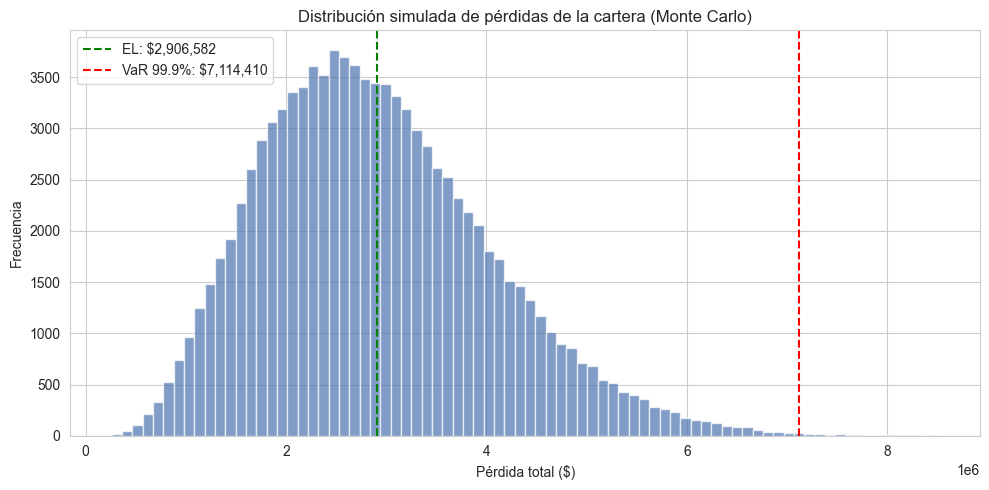

In [21]:
EL_teorica_pct = (pd_array * LGD_supuesto * ead_array).sum() / EAD_total
print(f"EL teórica (ponderada por EAD): {EL_teorica_pct*100:.2f}%")
print(f"EL simulada: {perdida_esperada_monto/EAD_total*100:.2f}%")
print(f"Diferencia: {abs(EL_teorica_pct*100 - perdida_esperada_monto/EAD_total*100):.4f} p.p. (debería ser cercana a 0)")

# Descomposición: ¿qué % de la EAD total está concentrado en el 10% de créditos de mayor PD?
cartera_ordenada = cartera.sort_values('PD', ascending=False)
top10_pct_creditos = int(len(cartera_ordenada) * 0.10)
ead_top10 = cartera_ordenada.iloc[:top10_pct_creditos]['Monto_Otorgado'].sum()
print(f"\nEAD concentrada en el 10% de créditos de mayor riesgo: {ead_top10/EAD_total*100:.2f}%")

# Distribución de las pérdidas simuladas (para visualizar la cola)
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.hist(perdidas_totales, bins=80, color='#4C72B0', alpha=0.7)
plt.axvline(perdida_esperada_monto, color='green', linestyle='--', label=f'EL: ${perdida_esperada_monto:,.0f}')
plt.axvline(VaR_999, color='red', linestyle='--', label=f'VaR 99.9%: ${VaR_999:,.0f}')
plt.title('Distribución simulada de pérdidas de la cartera (Monte Carlo)')
plt.xlabel('Pérdida total ($)')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
plt.savefig('distribucion_perdidas.png', dpi=110)
plt.show()

## Estimación de error de la simulación (convergencia y error estándar del VaR)

--- Convergencia del VaR según N de simulaciones ---
   n_simulaciones       VaR_999            EL  Capital_economico
0            1000  6.861865e+06  2.934782e+06       3.927083e+06
1            5000  6.948159e+06  2.925626e+06       4.022533e+06
2           10000  7.090388e+06  2.917106e+06       4.173282e+06
3           25000  7.131194e+06  2.896317e+06       4.234877e+06
4           50000  7.132761e+06  2.905010e+06       4.227751e+06
5          100000  7.188099e+06  2.910285e+06       4.277814e+06
6          250000  7.157159e+06  2.904486e+06       4.252673e+06

--- Error de estimación del VaR (100.000 sims, 30 repeticiones) ---
VaR promedio: $7,114,138
Error estándar: $32,041 (0.45% del VaR)
IC 95%: [$7,057,694 - $7,174,890]


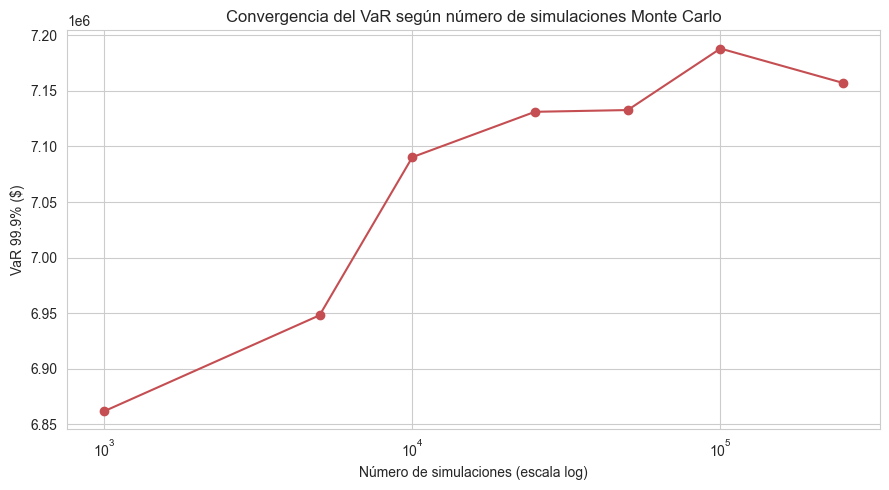

In [22]:
# Vectorizamos la simulación para poder correr múltiples tamaños de N rápidamente
def simular_perdidas_vectorizado(n_sim, pd_array, ead_array, lgd, rho, seed=42):
    rng_local = np.random.default_rng(seed)
    umbral = norm.ppf(pd_array)
    Z = rng_local.standard_normal(n_sim)
    epsilon = rng_local.standard_normal((n_sim, len(pd_array)))
    X = np.sqrt(rho) * Z[:, None] + np.sqrt(1 - rho) * epsilon
    defaults = X < umbral[None, :]
    perdidas = defaults @ (ead_array * lgd)
    return perdidas

# Convergencia: repetir la simulación con distintos N y ver cómo se estabiliza el VaR
tamanos_n = [1_000, 5_000, 10_000, 25_000, 50_000, 100_000, 250_000]
resultados_convergencia = []

for n in tamanos_n:
    perdidas_n = simular_perdidas_vectorizado(n, pd_array, ead_array, LGD_supuesto, rho, seed=42)
    var_n = np.percentile(perdidas_n, 99.9)
    el_n = perdidas_n.mean()
    resultados_convergencia.append({'n_simulaciones': n, 'VaR_999': var_n, 'EL': el_n, 'Capital_economico': var_n - el_n})

conv_df = pd.DataFrame(resultados_convergencia)
print("--- Convergencia del VaR según N de simulaciones ---")
print(conv_df)

# Error estándar del VaR: repetir la simulación de 100.000 varias veces con distintas semillas
n_repeticiones = 30
vars_repetidos = []
for rep in range(n_repeticiones):
    perdidas_rep = simular_perdidas_vectorizado(100_000, pd_array, ead_array, LGD_supuesto, rho, seed=rep)
    vars_repetidos.append(np.percentile(perdidas_rep, 99.9))

vars_repetidos = np.array(vars_repetidos)
error_estandar_var = vars_repetidos.std()
ic_95_var = np.percentile(vars_repetidos, [2.5, 97.5])

print(f"\n--- Error de estimación del VaR (100.000 sims, {n_repeticiones} repeticiones) ---")
print(f"VaR promedio: ${vars_repetidos.mean():,.0f}")
print(f"Error estándar: ${error_estandar_var:,.0f} ({error_estandar_var/vars_repetidos.mean()*100:.2f}% del VaR)")
print(f"IC 95%: [${ic_95_var[0]:,.0f} - ${ic_95_var[1]:,.0f}]")

plt.figure(figsize=(9, 5))
plt.plot(conv_df['n_simulaciones'], conv_df['VaR_999'], marker='o', color='#C44E52')
plt.xscale('log')
plt.xlabel('Número de simulaciones (escala log)')
plt.ylabel('VaR 99.9% ($)')
plt.title('Convergencia del VaR según número de simulaciones Monte Carlo')
plt.tight_layout()
plt.savefig('convergencia_var.png', dpi=110)
plt.show()

## Capital regulatorio estandarizado (BCRA) y comparación central: capital económico vs. regulatorio

--- Capital regulatorio estandarizado (BCRA, cartera minorista) ---
Ponderador de riesgo aplicado: 75%
Capital regulatorio: 6.00% de la EAD
Capital regulatorio en pesos: $1,531,860

--- Capital económico (IRB interno, Monte Carlo) ---
Capital económico: 16.48% de la EAD
Capital económico en pesos: $4,207,828

=== COMPARACIÓN CENTRAL: capital económico vs. regulatorio ===
Diferencia absoluta: $2,675,968
El capital económico es +174.7% respecto al regulatorio estandarizado

→ El capital económico (riesgo real medido) SUPERA al regulatorio estandarizado:
  el enfoque simple podría estar SUBESTIMANDO el riesgo real de esta cartera específica.


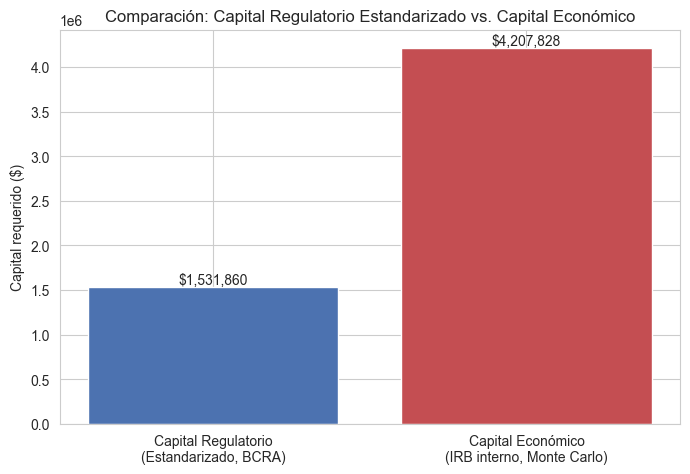

In [23]:
# Ponderador de riesgo estandarizado para cartera minorista diversificada (Basilea/BCRA)
ponderador_retail = 0.75
requerimiento_minimo = 0.08  # 8% de Basilea (Pilar 1, base)

capital_regulatorio_pct = ponderador_retail * requerimiento_minimo
capital_regulatorio_monto = EAD_total * capital_regulatorio_pct

print("--- Capital regulatorio estandarizado (BCRA, cartera minorista) ---")
print(f"Ponderador de riesgo aplicado: {ponderador_retail*100:.0f}%")
print(f"Capital regulatorio: {capital_regulatorio_pct*100:.2f}% de la EAD")
print(f"Capital regulatorio en pesos: ${capital_regulatorio_monto:,.0f}")

print(f"\n--- Capital económico (IRB interno, Monte Carlo) ---")
print(f"Capital económico: {capital_economico/EAD_total*100:.2f}% de la EAD")
print(f"Capital económico en pesos: ${capital_economico:,.0f}")

# La comparación central 
diferencia_absoluta = capital_economico - capital_regulatorio_monto
diferencia_pct = (capital_economico / capital_regulatorio_monto - 1) * 100

print(f"\n=== COMPARACIÓN CENTRAL: capital económico vs. regulatorio ===")
print(f"Diferencia absoluta: ${diferencia_absoluta:,.0f}")
print(f"El capital económico es {diferencia_pct:+.1f}% respecto al regulatorio estandarizado")

if capital_economico > capital_regulatorio_monto:
    print("\n→ El capital económico (riesgo real medido) SUPERA al regulatorio estandarizado:")
    print("  el enfoque simple podría estar SUBESTIMANDO el riesgo real de esta cartera específica.")
else:
    print("\n→ El capital económico (riesgo real medido) es MENOR al regulatorio estandarizado:")
    print("  el enfoque simple podría estar SOBRESTIMANDO el riesgo real de esta cartera,")
    print("  generando capital ocioso/ineficiente para el banco.")

# Gráfico comparativo
plt.figure(figsize=(7, 5))
barras = plt.bar(['Capital Regulatorio\n(Estandarizado, BCRA)', 'Capital Económico\n(IRB interno, Monte Carlo)'],
                  [capital_regulatorio_monto, capital_economico],
                  color=['#4C72B0', '#C44E52'])
for barra in barras:
    altura = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2, altura, f'${altura:,.0f}', ha='center', va='bottom')
plt.ylabel('Capital requerido ($)')
plt.title('Comparación: Capital Regulatorio Estandarizado vs. Capital Económico')
plt.tight_layout()
plt.savefig('comparacion_capital.png', dpi=110)
plt.show()

# Capítulo 6 — Valorización económica

## Escalado de la cartera a un tamaño de negocio de referencia ($500M)

In [24]:
# Escalar la cartera real a un tamaño de negocio de referencia (supuesto explícito para la tesis)
cartera_objetivo = 500_000_000  # $500M ARS, cartera hipotética de referencia
factor_escala = cartera_objetivo / EAD_total

EAD_escalada = EAD_total * factor_escala
EL_escalada = perdida_esperada_monto * factor_escala
VaR_escalado = VaR_999 * factor_escala
capital_economico_escalado = capital_economico * factor_escala
capital_regulatorio_escalado = capital_regulatorio_monto * factor_escala

print(f"--- Cartera escalada a ${cartera_objetivo:,.0f} (factor de escala: {factor_escala:.2f}x) ---")
print(f"EAD: ${EAD_escalada:,.0f}")
print(f"Pérdida Esperada (EL): ${EL_escalada:,.0f} ({EL_escalada/EAD_escalada*100:.2f}% de EAD)")
print(f"VaR 99.9%: ${VaR_escalado:,.0f}")
print(f"Capital económico: ${capital_economico_escalado:,.0f} ({capital_economico_escalado/EAD_escalada*100:.2f}% de EAD)")
print(f"Capital regulatorio estandarizado: ${capital_regulatorio_escalado:,.0f} ({capital_regulatorio_escalado/EAD_escalada*100:.2f}% de EAD)")

--- Cartera escalada a $500,000,000 (factor de escala: 19.58x) ---
EAD: $500,000,000
Pérdida Esperada (EL): $56,922,587 (11.38% de EAD)
VaR 99.9%: $139,328,815
Capital económico: $82,406,228 (16.48% de EAD)
Capital regulatorio estandarizado: $30,000,000 (6.00% de EAD)


## Costo de oportunidad del capital inmovilizado

In [25]:
costo_capital_anual = 0.17  # 17% anual, dentro del rango típico (15-20%) para banca en Argentina — supuesto a documentar

costo_oportunidad_regulatorio = capital_regulatorio_escalado * costo_capital_anual
costo_oportunidad_economico = capital_economico_escalado * costo_capital_anual

print(f"--- Costo de oportunidad anual del capital inmovilizado (costo de capital: {costo_capital_anual*100:.0f}%) ---")
print(f"Capital regulatorio (${capital_regulatorio_escalado:,.0f}) -> Costo anual: ${costo_oportunidad_regulatorio:,.0f}")
print(f"Capital económico (${capital_economico_escalado:,.0f}) -> Costo anual: ${costo_oportunidad_economico:,.0f}")
print(f"\nDiferencia de costo de oportunidad anual: ${costo_oportunidad_economico - costo_oportunidad_regulatorio:,.0f}")

# Pérdida esperada + costo de capital = "costo total de riesgo" anual bajo cada enfoque
costo_total_regulatorio = EL_escalada + costo_oportunidad_regulatorio
costo_total_economico = EL_escalada + costo_oportunidad_economico

print(f"\n--- Costo total de riesgo anual (EL + costo de oportunidad del capital) ---")
print(f"Bajo enfoque regulatorio estandarizado: ${costo_total_regulatorio:,.0f}")
print(f"Bajo enfoque económico (IRB interno): ${costo_total_economico:,.0f}")

--- Costo de oportunidad anual del capital inmovilizado (costo de capital: 17%) ---
Capital regulatorio ($30,000,000) -> Costo anual: $5,100,000
Capital económico ($82,406,228) -> Costo anual: $14,009,059

Diferencia de costo de oportunidad anual: $8,909,059

--- Costo total de riesgo anual (EL + costo de oportunidad del capital) ---
Bajo enfoque regulatorio estandarizado: $62,022,587
Bajo enfoque económico (IRB interno): $70,931,646


**Nota sobre el costo de capital.** El 17% anual es un supuesto del modelo y su nivel debe leerse con cuidado: las tasas activas usadas más adelante (65% anual) están expresadas en pesos nominales, en un contexto de inflación alta. Un costo de capital del 17% solo es comparable si se interpreta como una tasa **real**; en términos nominales sería considerablemente más alto. Para no depender de un único valor, se muestra la diferencia de costo de oportunidad bajo distintos niveles de costo de capital.

In [26]:
print("--- Sensibilidad del costo de oportunidad al costo de capital ---")
for k in [0.17, 0.30, 0.45, 0.65]:
    dif = (capital_economico_escalado - capital_regulatorio_escalado) * k
    print(f"Costo de capital {k*100:.0f}% -> diferencia anual: ${dif:,.0f}")


--- Sensibilidad del costo de oportunidad al costo de capital ---
Costo de capital 17% -> diferencia anual: $8,909,059
Costo de capital 30% -> diferencia anual: $15,721,868
Costo de capital 45% -> diferencia anual: $23,582,803
Costo de capital 65% -> diferencia anual: $34,064,048


## Verificación de invarianza de la EL y valor de rechazar el 10% de mayor riesgo

In [27]:
# --- Parte 1: verificación de invarianza de la EL ---
EL_con_modelo_pct = perdida_esperada_monto / EAD_total  # % de EL sobre EAD, con PD individual (Capítulo 5)

pd_promedio_ponderado = (pd_array * ead_array).sum() / ead_array.sum()
EL_ingenua_pct_correcta = pd_promedio_ponderado * LGD_supuesto
EL_ingenua_escalada_correcta = EL_ingenua_pct_correcta * EAD_escalada

print(f"--- Comparación corregida (misma metodología de ponderación) ---")
print(f"EL con PD promedio ponderada (sin discriminar riesgo individual): ${EL_ingenua_escalada_correcta:,.0f} ({EL_ingenua_pct_correcta*100:.2f}% EAD)")
print(f"EL con PD individual (modelo de scoring): ${EL_escalada:,.0f} ({EL_con_modelo_pct*100:.2f}% EAD)")
print(f"Diferencia: ${abs(EL_ingenua_escalada_correcta - EL_escalada):,.2f} (debería ser ~0, confirma que la EL total es invariante a la granularidad de PD)")

# --- Parte 2: valor de rechazar el 10% de créditos de mayor riesgo (identificados por el modelo) ---
cartera_ordenada = cartera.sort_values('PD', ascending=False).copy()
n_rechazar = int(len(cartera_ordenada) * 0.10)

ead_rechazados = cartera_ordenada.iloc[:n_rechazar]['Monto_Otorgado'].sum()
el_rechazados = (cartera_ordenada.iloc[:n_rechazar]['PD'] * LGD_supuesto * cartera_ordenada.iloc[:n_rechazar]['Monto_Otorgado']).sum()

ead_rechazados_escalada = ead_rechazados * factor_escala
el_evitada_escalada = el_rechazados * factor_escala

print(f"\n--- Valor de rechazar el 10% de mayor riesgo (identificado por el modelo) ---")
print(f"EAD que se dejaría de otorgar: ${ead_rechazados_escalada:,.0f} ({ead_rechazados/EAD_total*100:.2f}% de la cartera)")
print(f"Pérdida esperada evitada (bruta): ${el_evitada_escalada:,.0f}")

--- Comparación corregida (misma metodología de ponderación) ---
EL con PD promedio ponderada (sin discriminar riesgo individual): $56,877,571 (11.38% EAD)
EL con PD individual (modelo de scoring): $56,922,587 (11.38% EAD)
Diferencia: $45,016.57 (debería ser ~0, confirma que la EL total es invariante a la granularidad de PD)

--- Valor de rechazar el 10% de mayor riesgo (identificado por el modelo) ---
EAD que se dejaría de otorgar: $33,418,266 (6.68% de la cartera)
Pérdida esperada evitada (bruta): $11,189,374


## Costo neto de la política de rechazo (margen resignado vs. pérdida evitada)

In [28]:
tasa_interes_anual = 0.65     # tasa activa anual — supuesto a documentar y ajustar
tasa_base_sin_riesgo = 0.35   # costo de fondeo + margen operativo, sin riesgo crediticio — supuesto

# Margen NETO que se resigna al rechazar: tasa cobrada menos costo de fondeo/operativo
margen_neto_anual = tasa_interes_anual - tasa_base_sin_riesgo
margen_resignado = ead_rechazados_escalada * margen_neto_anual
ahorro_neto = el_evitada_escalada - margen_resignado

print(f"--- Costo de rechazar el 10% de mayor riesgo (margen NETO resignado: {margen_neto_anual*100:.0f}% anual) ---")
print(f"Margen neto resignado: ${margen_resignado:,.0f}")
print(f"Pérdida esperada evitada: ${el_evitada_escalada:,.0f}")
print(f"\n=== Resultado neto de la política de rechazo ===")
print(f"Ahorro neto: ${ahorro_neto:,.0f}")

if ahorro_neto > 0:
    print("→ Rechazar el 10% de mayor riesgo conviene bajo estos supuestos: la pérdida evitada supera el margen neto resignado.")
else:
    print("→ Rechazar el 10% de mayor riesgo NO conviene bajo estos supuestos: se pierde más margen del que se ahorra en riesgo.")

# Sensibilidad: el resultado depende del costo de fondeo
print("\n--- Sensibilidad al costo de fondeo + margen operativo ---")
for base in [0.25, 0.30, 0.35, 0.40, 0.45]:
    neto = el_evitada_escalada - ead_rechazados_escalada * (tasa_interes_anual - base)
    print(f"Tasa base {base*100:.0f}% -> ahorro neto: ${neto:,.0f}")

base_equilibrio = tasa_interes_anual - el_evitada_escalada / ead_rechazados_escalada
print(f"\nTasa base de equilibrio: {base_equilibrio*100:.1f}% (por debajo, rechazar no conviene; por encima, sí)")


--- Costo de rechazar el 10% de mayor riesgo (margen NETO resignado: 30% anual) ---
Margen neto resignado: $10,025,480
Pérdida esperada evitada: $11,189,374

=== Resultado neto de la política de rechazo ===
Ahorro neto: $1,163,894
→ Rechazar el 10% de mayor riesgo conviene bajo estos supuestos: la pérdida evitada supera el margen neto resignado.

--- Sensibilidad al costo de fondeo + margen operativo ---
Tasa base 25% -> ahorro neto: $-2,177,932
Tasa base 30% -> ahorro neto: $-507,019
Tasa base 35% -> ahorro neto: $1,163,894
Tasa base 40% -> ahorro neto: $2,834,807
Tasa base 45% -> ahorro neto: $4,505,721

Tasa base de equilibrio: 31.5% (por debajo, rechazar no conviene; por encima, sí)


## Valor del modelo vía re-pricing (discriminación de tasa, sin rechazar clientes)

In [29]:
# Re-pricing: en vez de rechazar, cobrar a cada segmento de riesgo una tasa que compense su PD real
# Tasa "justa" simplificada: tasa base (costo de fondeo + margen operativo) + prima de riesgo (PD × LGD, anualizada)

tasa_base_sin_riesgo = 0.35  # costo de fondeo + margen operativo, sin componente de riesgo crediticio — supuesto

cartera_repricing = cartera.copy()
cartera_repricing['prima_riesgo'] = cartera_repricing['PD'] * LGD_supuesto
cartera_repricing['tasa_justa'] = tasa_base_sin_riesgo + cartera_repricing['prima_riesgo']

# Comparar tasa única actual (65% para todos) vs. tasa diferenciada por riesgo
cartera_repricing['tasa_actual'] = tasa_interes_anual

print("--- Distribución de la tasa 'justa' según riesgo individual ---")
print(cartera_repricing['tasa_justa'].describe())

# ¿Cuántos créditos están mal pricéados con la tasa única? (tasa actual insuficiente para su riesgo real)
mal_pricéados = cartera_repricing[cartera_repricing['tasa_justa'] > cartera_repricing['tasa_actual']]
bien_pricéados = cartera_repricing[cartera_repricing['tasa_justa'] <= cartera_repricing['tasa_actual']]

print(f"\n--- Créditos sub-pricéados (tasa actual no cubre su riesgo real) ---")
print(f"Cantidad: {len(mal_pricéados)} de {len(cartera_repricing)} ({len(mal_pricéados)/len(cartera_repricing)*100:.1f}%)")
print(f"EAD involucrada: ${mal_pricéados['Monto_Otorgado'].sum() * factor_escala:,.0f}")

# Ingreso adicional si se re-pricea correctamente a los sub-pricéados (sin rechazar a nadie)
mal_pricéados = mal_pricéados.copy()
mal_pricéados['ingreso_adicional'] = (mal_pricéados['tasa_justa'] - mal_pricéados['tasa_actual']) * mal_pricéados['Monto_Otorgado']
ingreso_adicional_total = mal_pricéados['ingreso_adicional'].sum() * factor_escala

print(f"\n=== Valor del re-pricing (sin rechazar ningún cliente) ===")
print(f"Ingreso adicional anual por cobrar tasa acorde al riesgo real: ${ingreso_adicional_total:,.0f}")
print(f"Esto compensa/reduce la pérdida esperada de esos créditos sin resignar margen de negocio.")

--- Distribución de la tasa 'justa' según riesgo individual ---
count    831.000000
mean       0.489920
std        0.098538
min        0.351497
25%        0.413586
50%        0.459881
75%        0.555521
max        0.770596
Name: tasa_justa, dtype: float64

--- Créditos sub-pricéados (tasa actual no cubre su riesgo real) ---
Cantidad: 69 de 831 (8.3%)
EAD involucrada: $26,791,363

=== Valor del re-pricing (sin rechazar ningún cliente) ===
Ingreso adicional anual por cobrar tasa acorde al riesgo real: $1,183,634
Esto compensa/reduce la pérdida esperada de esos créditos sin resignar margen de negocio.


## Análisis de sensibilidad del capital económico (LGD y ρ) y rango final de valorización

--- Sensibilidad del capital económico a LGD (con ρ=0.15 fijo) ---
 valor    EL_pct  capital_pct  capital_monto_escalado
  0.35  8.823353    12.901149            6.450574e+07
  0.40 10.083832    14.744170            7.372085e+07
  0.45 11.344311    16.587191            8.293596e+07
  0.50 12.604790    18.430212            9.215106e+07
  0.55 13.865269    20.273234            1.013662e+08
  0.60 15.125748    22.116255            1.105813e+08

--- Sensibilidad del capital económico a ρ (con LGD=0.45 fijo) ---
 valor    EL_pct  capital_pct  capital_monto_escalado
  0.03 11.362377     7.250754            3.625377e+07
  0.08 11.353130    11.800844            5.900422e+07
  0.15 11.344311    16.587191            8.293596e+07
  0.20 11.341907    19.118361            9.559180e+07
  0.25 11.336581    21.566406            1.078320e+08

=== RANGO DE VALORIZACIÓN DEL CAPITAL ECONÓMICO ===
Estimación puntual (LGD=45%, ρ=0.15): $82,406,228
Rango bajo supuestos alternativos plausibles: $36,253,771 - 

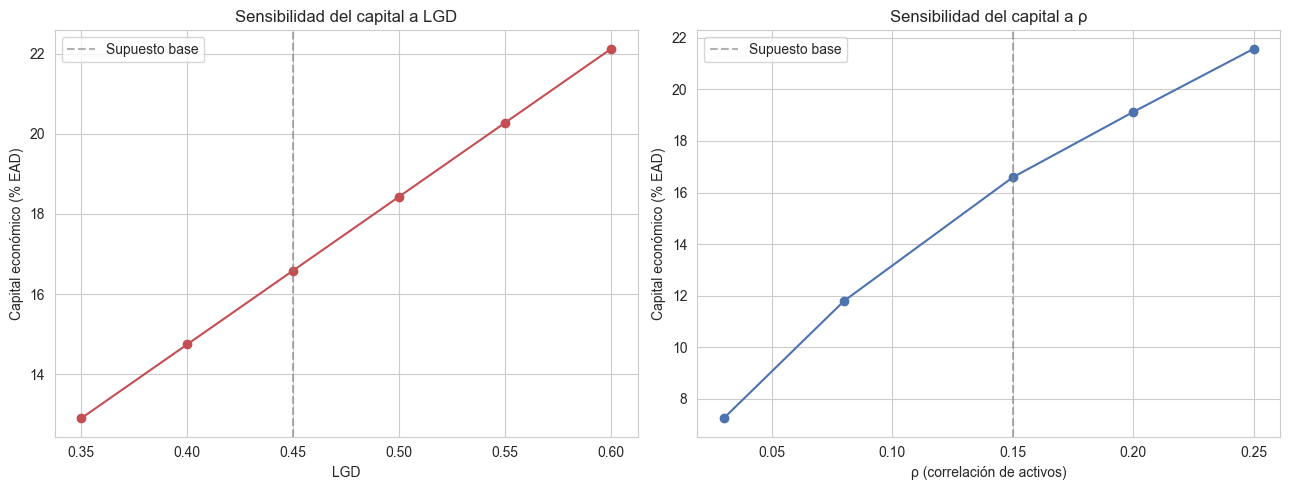

In [30]:
# Rangos de sensibilidad (variaciones razonables alrededor de los supuestos base)
lgd_rango = [0.35, 0.40, 0.45, 0.50, 0.55, 0.60]  # base: 0.45
rho_rango = [0.03, 0.08, 0.15, 0.20, 0.25]          # base: 0.15 (Basilea calibra 0.03-0.16 para minorista)

n_sim_sensibilidad = 25_000  # suficiente según el análisis de convergencia (celda 4 del cap 5), corre más rápido

resultados_sensibilidad = []

for lgd in lgd_rango:
    perdidas = simular_perdidas_vectorizado(n_sim_sensibilidad, pd_array, ead_array, lgd, rho, seed=42)
    el = perdidas.mean()
    var999 = np.percentile(perdidas, 99.9)
    capital = var999 - el
    resultados_sensibilidad.append({
        'parametro': 'LGD', 'valor': lgd,
        'EL_pct': el/EAD_total*100, 'capital_pct': capital/EAD_total*100,
        'capital_monto_escalado': capital * factor_escala
    })

for r in rho_rango:
    perdidas = simular_perdidas_vectorizado(n_sim_sensibilidad, pd_array, ead_array, LGD_supuesto, r, seed=42)
    el = perdidas.mean()
    var999 = np.percentile(perdidas, 99.9)
    capital = var999 - el
    resultados_sensibilidad.append({
        'parametro': 'rho', 'valor': r,
        'EL_pct': el/EAD_total*100, 'capital_pct': capital/EAD_total*100,
        'capital_monto_escalado': capital * factor_escala
    })

sens_df = pd.DataFrame(resultados_sensibilidad)
print("--- Sensibilidad del capital económico a LGD (con ρ=0.15 fijo) ---")
print(sens_df[sens_df['parametro']=='LGD'][['valor', 'EL_pct', 'capital_pct', 'capital_monto_escalado']].to_string(index=False))

print("\n--- Sensibilidad del capital económico a ρ (con LGD=0.45 fijo) ---")
print(sens_df[sens_df['parametro']=='rho'][['valor', 'EL_pct', 'capital_pct', 'capital_monto_escalado']].to_string(index=False))

# Rango de valorización final: capital mínimo y máximo dentro de los supuestos plausibles
capital_min = sens_df['capital_monto_escalado'].min()
capital_max = sens_df['capital_monto_escalado'].max()
print(f"\n=== RANGO DE VALORIZACIÓN DEL CAPITAL ECONÓMICO ===")
print(f"Estimación puntual (LGD=45%, ρ=0.15): ${capital_economico_escalado:,.0f}")
print(f"Rango bajo supuestos alternativos plausibles: ${capital_min:,.0f} - ${capital_max:,.0f}")

# Gráficos de sensibilidad
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sens_lgd = sens_df[sens_df['parametro']=='LGD']
axes[0].plot(sens_lgd['valor'], sens_lgd['capital_pct'], marker='o', color='#C44E52')
axes[0].axvline(0.45, color='gray', linestyle='--', alpha=0.6, label='Supuesto base')
axes[0].set_xlabel('LGD')
axes[0].set_ylabel('Capital económico (% EAD)')
axes[0].set_title('Sensibilidad del capital a LGD')
axes[0].legend()

sens_rho = sens_df[sens_df['parametro']=='rho']
axes[1].plot(sens_rho['valor'], sens_rho['capital_pct'], marker='o', color='#4C72B0')
axes[1].axvline(0.15, color='gray', linestyle='--', alpha=0.6, label='Supuesto base')
axes[1].set_xlabel('ρ (correlación de activos)')
axes[1].set_ylabel('Capital económico (% EAD)')
axes[1].set_title('Sensibilidad del capital a ρ')
axes[1].legend()

plt.tight_layout()
plt.savefig('sensibilidad_capital.png', dpi=110)
plt.show()

# Conclusiones

**Modelo de scoring.** La regresión logística WOE/IV de 4 variables (ingresos, consultas en 7 días, producto y provincia) alcanza un AUC de 0,69 en prueba (Gini 0,39; KS 0,37). Los modelos challenger (SVM, Random Forest, XGBoost y red neuronal) no se diferencian de forma estadísticamente clara del benchmark: los intervalos de confianza bootstrap se superponen. Se adopta la logística por su interpretabilidad. El poder discriminante es moderado y hay sobreajuste leve (AUC train 0,80 vs. test 0,69), esperable con 623 observaciones de entrenamiento.

**Capital.** Bajo el modelo de un factor sistémico (Vasicek; LGD 45%, ρ 0,15, confianza 99,9%), el capital económico es del 16,5% de la exposición, frente al 6,0% del enfoque regulatorio estandarizado (+175%). En esta cartera, con una mora del 31%, el enfoque simple subestimaría el riesgo. La magnitud depende de LGD y ρ: la sensibilidad lleva el capital económico de $36 M a $111 M para una cartera de $500 M, y en todo el rango analizado el capital económico estimado se mantiene por encima del regulatorio.

**Valor económico.** Rechazar al 10% de mayor riesgo arroja un ahorro neto de aproximadamente +$1,2 M con un costo de fondeo del 35%, pero el resultado cambia de signo si ese costo baja de ~31,5%. El re-pricing por riesgo, en cambio, no depende de rechazar a nadie: 69 créditos (8,3%) están sub-pricéados y corregir su tasa aportaría unos $1,2 M anuales.

**Limitaciones.** Muestra reducida; LGD, ρ, costo de capital y tasas son supuestos y no estimaciones; la exposición se aproxima con el monto otorgado; la PD se asigna a toda la cartera con un modelo entrenado sobre el 75% de ella; y el cálculo compara pérdida esperada y margen sobre un horizonte comparable (~1 año). Los resultados son ilustrativos de la metodología, no una recomendación de capital para una entidad real.
